# Baseline MobileNetV3-Large on PlantVillage: 1-epoch check + T4 timing

This notebook is the first end-to-end run of the training pipeline. It:

1. loads a split manifest (`splits_demo1_13c.csv` for Demo 1, `splits_all_38c.csv` for all 38 classes),
2. builds `mobilenet_v3_large` (ImageNet weights) with a new linear head sized to the number of classes,
3. trains with a **class-weighted** `CrossEntropyLoss` for **1 epoch**, then runs a validation pass,
4. exports a dummy `.onnx` and checks it against PyTorch,
5. records the **exact time per epoch** so we can report the training budget.

**Outputs** (folder `/content/outputs`): one `.pt` checkpoint, one `.onnx` and one `timing_*.json` per configuration.

## 1. Setup

Install the ONNX packages (not preinstalled on Colab), import everything in one place and check that a GPU is attached.

In [1]:
import subprocess
import sys

pip = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime", "onnxscript"],
    capture_output=True,
    text=True,
)
print("pip exit code:", pip.returncode, pip.stderr[-300:])

pip exit code: 0 


In [2]:
import gc
import json
import os
import random
import shutil
import subprocess
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from IPython.display import display
from PIL import Image
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "No GPU found: Runtime > Change runtime type > T4 GPU"
device = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)
print(GPU_NAME, "| torch", torch.__version__)
if "T4" not in GPU_NAME:
    print("WARNING: timings are only valid for a T4, this runtime has", GPU_NAME)
print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)

Tesla T4 | torch 2.11.0+cu130
Mon Nov  2 10:15:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------

## 2. Configuration

Everything you may want to change is in this cell.

* `CONFIGS` maps a config name to its manifest and to the column used as the class label
  (`demo1_id` is 0..12 for the 13 Demo 1 classes, `class_id` is 0..37 for all classes).
* `CONFIGS_TO_RUN` is the toggle: keep both to get both timings in one run, or use `["demo1_13c"]` for a quick run.
* `REVISION` pins the Hugging Face dataset commit, so the images match the manifests.
* `HP["epochs"] = 1` is deliberate for this task: the point is a working pipeline and an exact epoch time.

In [ ]:
REVISION = "9e97599868962bd0079b8db4b7f1efa9185fa1e7"  # pinned mohanty/PlantVillage commit

CONFIGS = {
    "demo1_13c": {"manifest": "splits_demo1_13c.csv", "target": "demo1_id"},
    "all_38c": {"manifest": "splits_all_38c.csv", "target": "class_id"},
}
CONFIGS_TO_RUN = ["demo1_13c", "all_38c"]  # use ["demo1_13c"] to run only Demo 1

HP = {
    "epochs": 1,
    "batch_size": 64,
    "lr": 5e-4,
    "weight_decay": 1e-4,
    "img_size": 224,
    "workers": min(os.cpu_count() or 2, 8),
    "amp": True,
    "seed": 42,
}

WORK = Path("/content/work")
MANIFEST_DIR = WORK / "datasets"
LABELS_PATH = WORK / "labels.csv"
IMG_ROOT = Path("/content/plantvillage")
OUT_DIR = Path("/content/outputs")
for d in (MANIFEST_DIR, IMG_ROOT, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(HP["seed"])
np.random.seed(HP["seed"])
torch.manual_seed(HP["seed"])
torch.backends.cudnn.benchmark = True

## 3. Load the manifests and `labels.csv`

If the files are not on disk yet, Colab asks you to upload them. (If you cloned the repo instead,
point `MANIFEST_DIR` and `LABELS_PATH` in section 2 at the cloned folders.)

`labels.csv` lists **only the 13 Demo 1 classes**, so it sizes the Demo 1 head.
For the 38-class run the head size comes from the manifest.

In [8]:
needed = [MANIFEST_DIR / CONFIGS[c]["manifest"] for c in CONFIGS_TO_RUN]
missing = [p for p in needed if not p.exists()]
from google.colab import files

if missing:
    print("Select these files:", [p.name for p in missing])
    for fname, data in files.upload().items():
        target_path = MANIFEST_DIR / fname
        target_path.write_bytes(data)
if not LABELS_PATH.exists():
    print("Select labels.csv file")
    for fname, data in files.upload().items():
        target_path = LABELS_PATH
        target_path.write_bytes(data)
for p in needed:
    assert p.exists(), f"missing {p}"

labels = pd.read_csv(LABELS_PATH)
manifests = {c: pd.read_csv(MANIFEST_DIR / CONFIGS[c]["manifest"]) for c in CONFIGS_TO_RUN}
for c, m in manifests.items():
    print(c, len(m), "images", m["split"].value_counts().to_dict())
display(labels[["class_id", "demo1_id", "crop", "disease"]])

Select labels.csv file


Saving labels.csv to labels.csv
demo1_13c 20312 images {'train': 14102, 'val': 3146, 'test': 3064}
all_38c 54305 images {'train': 37951, 'test': 8184, 'val': 8170}


,class_id,demo1_id,crop,disease
0,20,0,potato,early_blight
1,22,1,potato,healthy
2,21,2,potato,late_blight
3,28,3,tomato,bacterial_spot
4,29,4,tomato,early_blight
5,37,5,tomato,healthy
6,30,6,tomato,late_blight
7,31,7,tomato,leaf_mold
8,36,8,tomato,mosaic_virus
9,32,9,tomato,septoria_leaf_spot


## 4. Download and extract the images

The manifests only list file paths. The images come from `data.zip` (about 2.2 GB) in the
`mohanty/PlantVillage` dataset repo. We extract **only the files the manifests need**, to local disk.
This step is not part of the epoch timing.

In [9]:
t0 = time.perf_counter()
zip_path = hf_hub_download(
    "mohanty/PlantVillage", "data.zip", repo_type="dataset", revision=REVISION
)
print(f"data.zip ready in {time.perf_counter() - t0:.0f}s")

wanted = sorted(set().union(*(set(m["path"]) for m in manifests.values())))
todo = [p for p in wanted if not (IMG_ROOT / p).exists()]
print(f"{len(wanted)} images needed, {len(todo)} still to extract")
if todo:
    with zipfile.ZipFile(zip_path) as zf:
        for p in tqdm(todo):
            zf.extract(p, IMG_ROOT)
assert all((IMG_ROOT / p).exists() for p in wanted), "some images are missing after extraction"

data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

data.zip ready in 27s
54305 images needed, 54305 still to extract


  0%|          | 0/54305 [00:00<?, ?it/s]

## 5. Dataset and data loaders

Images are 256x256 JPEGs. Training uses a random crop/flip, validation a plain resize to 224x224,
both normalised with the ImageNet statistics the pretrained weights expect.
The path column in the manifest is relative to `IMG_ROOT`.

In [10]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
SIZE = HP["img_size"]

train_tfm = transforms.Compose(
    [
        transforms.RandomResizedCrop(SIZE, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ]
)
eval_tfm = transforms.Compose(
    [
        transforms.Resize((SIZE, SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ]
)


class LeafDataset(Dataset):
    def __init__(self, df, target_col, tfm):
        self.paths = [str(IMG_ROOT / p) for p in df["path"]]
        self.targets = df[target_col].astype(int).tolist()
        self.tfm = tfm

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            x = self.tfm(img.convert("RGB"))
        return x, self.targets[i]


def make_loader(df, target_col, train):
    return DataLoader(
        LeafDataset(df, target_col, train_tfm if train else eval_tfm),
        batch_size=HP["batch_size"],
        shuffle=train,
        num_workers=HP["workers"],
        pin_memory=True,
        persistent_workers=HP["workers"] > 0,
        drop_last=train,
    )

## 6. Model and class weights

* `build_model` loads `mobilenet_v3_large(weights="DEFAULT")` and replaces the last `Linear` layer
  (the 1000-class ImageNet head) with a new one of size `num_classes`.
* `class_weights` computes inverse-frequency weights from the **training split only**:
  `weight_c = N / (K * n_c)`. A class with few images (Potato healthy, 152) gets a large weight,
  a class with many (Tomato yellow leaf curl virus, 5,375) a small one, so rare classes are not ignored.
  The weights are passed to `CrossEntropyLoss(weight=...)`.

In [11]:
def build_model(num_classes, pretrained=True):
    model = models.mobilenet_v3_large(weights="DEFAULT" if pretrained else None)
    in_features = model.classifier[-1].in_features
    model.classifier[-1] = nn.Linear(in_features, num_classes)
    return model


def class_weights(train_targets, num_classes):
    counts = np.bincount(train_targets, minlength=num_classes)
    assert (counts > 0).all(), "a class has no training images"
    weights = counts.sum() / (num_classes * counts)
    return torch.tensor(weights, dtype=torch.float32), counts

## 7. Training and evaluation functions (with timing)

Both functions call `torch.cuda.synchronize()` before and after timing, because CUDA runs asynchronously
and without it the clock would stop before the GPU is done.

* `train_one_epoch` also records `data_wait_sec`: time the training loop spent waiting for the next batch.
  If it is a large share of the epoch, the Colab CPUs (JPEG decoding) are the bottleneck, not the T4.
* `evaluate` reports an unweighted validation loss, accuracy and macro F1 (macro F1 matters here because of the class imbalance).

In [12]:
def sync():
    torch.cuda.synchronize()


def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    loss_sum = torch.zeros((), device=device)
    n, data_wait = 0, 0.0
    sync()
    t_start = t_fetch = time.perf_counter()
    for x, y in loader:
        data_wait += time.perf_counter() - t_fetch
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=HP["amp"]):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        loss_sum += loss.detach() * len(y)
        n += len(y)
        t_fetch = time.perf_counter()
    sync()
    return {
        "loss": float(loss_sum) / n,
        "seconds": time.perf_counter() - t_start,
        "data_wait_sec": data_wait,
        "images": n,
    }


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum = torch.zeros((), device=device)
    preds, targets = [], []
    sync()
    t_start = time.perf_counter()
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=HP["amp"]):
            logits = model(x)
        loss_sum += F.cross_entropy(logits.float(), y, reduction="sum")
        preds.append(logits.argmax(1).cpu())
        targets.append(y.cpu())
    sync()
    seconds = time.perf_counter() - t_start
    preds = torch.cat(preds).numpy()
    targets = torch.cat(targets).numpy()
    return {
        "loss": float(loss_sum) / len(targets),
        "acc": float((preds == targets).mean()),
        "macro_f1": float(f1_score(targets, preds, average="macro")),
        "seconds": seconds,
        "images": len(targets),
    }

## 8. Run: 1 epoch per configuration
 trains 1 epoch and runs the validation pass, timing the whole epoch (train + validation),
3. saves the checkpoint `mobilenetv3_<config>_epoch1.pt` and the metrics `timing_<config>.json`.

!! The first epoch includes one-off costs so it is slightly
slower than later epochs.

In [13]:
def run_config(name):
    target = CONFIGS[name]["target"]
    df = manifests[name]
    train_df, val_df = df[df["split"] == "train"], df[df["split"] == "val"]

    # head size: Demo 1 comes from labels.csv (13 rows), the 38-class run from the manifest
    num_classes = len(labels) if target == "demo1_id" else int(df[target].nunique())
    ids = sorted(df[target].astype(int).unique())
    assert ids == list(range(num_classes)), "class ids must be exactly 0..K-1"
    first = df.drop_duplicates(target).sort_values(target)
    class_names = (first["crop"] + "___" + first["disease"]).tolist()

    weights, counts = class_weights(train_df[target].astype(int).to_numpy(), num_classes)
    table = pd.DataFrame(
        {"class": class_names, "train_images": counts, "weight": weights.numpy().round(2)}
    )
    print(f"=== {name}: {num_classes} classes, {len(train_df)} train / {len(val_df)} val ===")
    display(table)

    model = build_model(num_classes).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights.to(device))
    optimizer = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    scaler = torch.amp.GradScaler("cuda", enabled=HP["amp"])
    train_loader = make_loader(train_df, target, train=True)
    val_loader = make_loader(val_df, target, train=False)

    torch.cuda.reset_peak_memory_stats()
    epochs = []
    for epoch in range(1, HP["epochs"] + 1):
        sync()
        t0 = time.perf_counter()
        tr = train_one_epoch(model, train_loader, criterion, optimizer, scaler)
        va = evaluate(model, val_loader)
        sync()
        epoch_sec = time.perf_counter() - t0
        epochs.append({"epoch": epoch, "epoch_sec": epoch_sec, "train": tr, "val": va})
        print(
            f"epoch {epoch}: {epoch_sec:.1f}s total "
            f"(train {tr['seconds']:.1f}s + val {va['seconds']:.1f}s) | "
            f"train loss {tr['loss']:.3f} | val acc {va['acc']:.3f} | "
            f"val macro F1 {va['macro_f1']:.3f}"
        )

    ckpt_path = OUT_DIR / f"mobilenetv3_{name}_epoch{HP['epochs']}.pt"
    torch.save(
        {
            "state_dict": model.state_dict(),
            "num_classes": num_classes,
            "class_names": class_names,
            "config": name,
            "epochs_trained": HP["epochs"],
            "img_size": SIZE,
            "mean": MEAN,
            "std": STD,
        },
        ckpt_path,
    )

    last = epochs[-1]
    record = {
        "config": name,
        "num_classes": num_classes,
        "train_images": len(train_df),
        "val_images": len(val_df),
        "sec_per_epoch": float(np.mean([e["epoch_sec"] for e in epochs])),
        "train_sec": last["train"]["seconds"],
        "val_sec": last["val"]["seconds"],
        "train_img_per_s": last["train"]["images"] / last["train"]["seconds"],
        "data_wait_pct": 100 * last["train"]["data_wait_sec"] / last["train"]["seconds"],
        "peak_mem_gb": torch.cuda.max_memory_allocated() / 1e9,
        "val_acc": last["val"]["acc"],
        "val_macro_f1": last["val"]["macro_f1"],
        "gpu": GPU_NAME,
        "torch": torch.__version__,
        "hp": HP,
        "epochs": epochs,
    }
    (OUT_DIR / f"timing_{name}.json").write_text(json.dumps(record, indent=2))

    del train_loader, val_loader, model, optimizer
    gc.collect()
    torch.cuda.empty_cache()
    return record


RESULTS = {name: run_config(name) for name in CONFIGS_TO_RUN}

=== demo1_13c: 13 classes, 14102 train / 3146 val ===


,class,train_images,weight
0,Potato___Early_blight,660,1.64
1,Potato___healthy,92,11.79
2,Potato___Late_blight,712,1.52
3,Tomato___Bacterial_spot,1436,0.76
4,Tomato___Early_blight,732,1.48
5,Tomato___healthy,1098,0.99
6,Tomato___Late_blight,1352,0.80
7,Tomato___Leaf_Mold,624,1.74
8,Tomato___Tomato_mosaic_virus,279,3.89
9,Tomato___Septoria_leaf_spot,1250,0.87


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 174MB/s]


epoch 1: 87.2s total (train 77.3s + val 9.9s) | train loss 0.300 | val acc 0.962 | val macro F1 0.956
=== all_38c: 38 classes, 37951 train / 8170 val ===


,class,train_images,weight
0,Apple___Apple_scab,452,2.21
1,Apple___Black_rot,436,2.29
2,Apple___Cedar_apple_rust,219,4.56
3,Apple___healthy,1196,0.84
4,Blueberry___healthy,1034,0.97
5,Cherry_(including_sour)___Powdery_mildew,769,1.30
6,Cherry_(including_sour)___healthy,577,1.73
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,376,2.66
8,Corn_(maize)___Common_rust_,818,1.22
9,Corn_(maize)___Northern_Leaf_Blight,688,1.45


epoch 1: 167.2s total (train 143.7s + val 23.5s) | train loss 0.256 | val acc 0.985 | val macro F1 0.979


## 9. Dummy ONNX export check

For every checkpoint from section 8 this cell rebuilds the model on CPU, exports it to ONNX with a dynamic batch axis,
validates the file with `onnx.checker`, runs it with `onnxruntime` on a batch of 2 and asserts that the output
matches PyTorch (max difference below 1e-3). This proves the exported head and the 224x224 input shape work end to end.

In [14]:
def onnx_check(name):
    import onnx
    import onnxruntime as ort

    ckpt = torch.load(OUT_DIR / f"mobilenetv3_{name}_epoch{HP['epochs']}.pt", map_location="cpu")
    model = build_model(ckpt["num_classes"], pretrained=False)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()

    onnx_path = OUT_DIR / f"mobilenetv3_{name}.onnx"
    dummy = torch.randn(1, 3, SIZE, SIZE)
    export_kwargs = {
        "input_names": ["input"],
        "output_names": ["logits"],
        "dynamic_axes": {"input": {0: "batch"}, "logits": {0: "batch"}},
        "opset_version": 17,
    }
    try:
        torch.onnx.export(model, dummy, str(onnx_path), dynamo=False, **export_kwargs)
    except TypeError:  # older torch has no `dynamo` argument
        torch.onnx.export(model, dummy, str(onnx_path), **export_kwargs)

    onnx.checker.check_model(onnx.load(str(onnx_path)))
    session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
    batch = torch.randn(2, 3, SIZE, SIZE)  # batch of 2 also checks the dynamic batch axis
    with torch.no_grad():
        expected = model(batch).numpy()
    got = session.run(None, {"input": batch.numpy()})[0]
    max_diff = float(np.abs(expected - got).max())
    assert got.shape == (2, ckpt["num_classes"]), got.shape
    assert max_diff < 1e-3, f"ONNX output differs from PyTorch by {max_diff}"
    print(f"{name}: ONNX ok | {onnx_path.stat().st_size / 1e6:.1f} MB | max diff {max_diff:.2e}")


for name in CONFIGS_TO_RUN:
    onnx_check(name)

/tmp/ipykernel_808/1174517196.py:19: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, str(onnx_path), dynamo=False, **export_kwargs)


demo1_13c: ONNX ok | 16.9 MB | max diff 5.13e-06
all_38c: ONNX ok | 17.0 MB | max diff 3.34e-06


## 10. Timing summary and training budget

Reads every `timing_*.json` in the output folder and prints one row per configuration.
The last three columns project the training time for 10, 20 and 30 epochs from the measured epoch time
(a simple multiplication, so it is only as good as the one-epoch measurement).

How to read it:

* `sec_per_epoch` is train + validation time on the T4: **the number to report to the mentor**.
* `data_wait_pct` close to 0 means the GPU is the bottleneck; a high value means the loader (Colab CPUs) is.
* The `val_acc` and `val_macro_f1` after one epoch only show that the pipeline learns, they are not the final model quality.

In [15]:
rows = []
for path in sorted(OUT_DIR.glob("timing_*.json")):
    r = json.loads(path.read_text())
    rows.append(
        {
            "config": r["config"],
            "classes": r["num_classes"],
            "train_imgs": r["train_images"],
            "val_imgs": r["val_images"],
            "sec_per_epoch": round(r["sec_per_epoch"], 1),
            "train_sec": round(r["train_sec"], 1),
            "val_sec": round(r["val_sec"], 1),
            "train_img_per_s": round(r["train_img_per_s"]),
            "data_wait_pct": round(r["data_wait_pct"]),
            "peak_mem_gb": round(r["peak_mem_gb"], 2),
            "val_acc": round(r["val_acc"], 3),
            "val_macro_f1": round(r["val_macro_f1"], 3),
            "gpu": r["gpu"],
        }
    )
summary = pd.DataFrame(rows)
for n_epochs in (10, 20, 30):
    summary[f"{n_epochs} epochs (min)"] = (summary["sec_per_epoch"] * n_epochs / 60).round(1)
display(summary)

,config,classes,train_imgs,val_imgs,sec_per_epoch,train_sec,val_sec,train_img_per_s,data_wait_pct,peak_mem_gb,val_acc,val_macro_f1,gpu,10 epochs (min),20 epochs (min),30 epochs (min)
0,all_38c,38,37951,8170,167.2,143.7,23.5,264,38,1.56,0.985,0.979,Tesla T4,27.9,55.7,83.6
1,demo1_13c,13,14102,3146,87.2,77.3,9.9,182,24,1.56,0.962,0.956,Tesla T4,14.5,29.1,43.6


## 11. Keep the results

Everything is in `/content/outputs`, which disappears when the Colab runtime is recycled.
Set `USE_DRIVE = True` to copy it to Google Drive, otherwise the folder is zipped for download.

In [16]:
USE_DRIVE = False

print(sorted(p.name for p in OUT_DIR.iterdir()))
if USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    dest = Path("/content/drive/MyDrive/rootine/baseline_mobilenetv3")
    dest.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(OUT_DIR, dest, dirs_exist_ok=True)
    print("copied to", dest)
else:
    from google.colab import files

    archive = shutil.make_archive("/content/baseline_outputs", "zip", OUT_DIR)
    files.download(archive)

['mobilenetv3_all_38c.onnx', 'mobilenetv3_all_38c_epoch1.pt', 'mobilenetv3_demo1_13c.onnx', 'mobilenetv3_demo1_13c_epoch1.pt', 'timing_all_38c.json', 'timing_demo1_13c.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import hashlib
from pathlib import Path

p = Path("/content/work/datasets/splits_all_38c.csv")
print("md5:", hashlib.md5(p.read_bytes()).hexdigest())
df_old = pd.read_csv(p)
print(df_old.columns.tolist())
print(df_old["split"].value_counts().to_dict())

md5: ece5e4f295a69abdaa907eb4dd9facc9
['path', 'leaf_id', 'crop', 'disease', 'class_id', 'demo1_id', 'split']
{'train': 37951, 'test': 8184, 'val': 8170}


In [18]:
# Test-set evaluation: run ONCE, after all tuning is finished
test_df = manifests["all_38c"].query("split == 'test'")
print("test images:", len(test_df), "| classes:", test_df["class_id"].nunique())

ckpt = torch.load(OUT_DIR / "mobilenetv3_all_38c_epoch1.pt", map_location="cpu")
model = build_model(ckpt["num_classes"], pretrained=False)
model.load_state_dict(ckpt["state_dict"])
model.to(device)

test_loader = make_loader(test_df, "class_id", train=False)
res = evaluate(model, test_loader)
print(f"TEST  acc {res['acc']:.4f} | macro F1 {res['macro_f1']:.4f} | loss {res['loss']:.4f}")

(OUT_DIR / "test_all_38c.json").write_text(json.dumps(res, indent=2))

test images: 8184 | classes: 38
TEST  acc 0.9836 | macro F1 0.9791 | loss 0.0462


147

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

# Change these paths to match your setup
CSV_PATH = "/content/work/datasets/splits_all_38c.csv"
IMAGE_ROOT = Path("/content/PlantVillage")

df = pd.read_csv(CSV_PATH)
print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Columns:
['path', 'leaf_id', 'crop', 'disease', 'class_id', 'demo1_id', 'split']

First 5 rows:


,path,leaf_id,crop,disease,class_id,demo1_id,split
0,raw/color/Apple___Apple_scab/00075aa8-d81a-418...,Apple___Apple_scab:::79.0,Apple,Apple_scab,0,NaN,test
1,raw/color/Apple___Apple_scab/01a66316-0e98-4d3...,Apple___Apple_scab:::19.0,Apple,Apple_scab,0,NaN,val
2,raw/color/Apple___Apple_scab/01f3deaa-6143-4b6...,Apple___Apple_scab:::39.0,Apple,Apple_scab,0,NaN,val
3,raw/color/Apple___Apple_scab/0208f4eb-45a4-439...,Apple___Apple_scab:::25.0,Apple,Apple_scab,0,NaN,train
4,raw/color/Apple___Apple_scab/023123cb-7b69-4c9...,Apple___Apple_scab:::102.0,Apple,Apple_scab,0,NaN,train


In [21]:
def show_train_val_images(df, class_name, image_root, n=5, seed=42):
    rng = random.Random(seed)

    train_df = df[(df["class_name"] == class_name) & (df["split"] == "train")]

    val_df = df[(df["class_name"] == class_name) & (df["split"] == "val")]

    if len(train_df) == 0 or len(val_df) == 0:
        print(f"No train or validation images found for {class_name}")
        return

    n = min(n, len(train_df), len(val_df))

    train_samples = train_df.sample(n=n, random_state=seed)
    val_samples = val_df.sample(n=n, random_state=seed)

    fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(10, 4 * n))

    if n == 1:
        axes = [axes]

    for i, (_, train_row) in enumerate(train_samples.iterrows()):
        _, val_row = list(val_samples.iterrows())[i]

        train_path = image_root / train_row["path"]
        val_path = image_root / val_row["path"]

        train_img = Image.open(train_path).convert("RGB")
        val_img = Image.open(val_path).convert("RGB")

        axes[i][0].imshow(train_img)
        axes[i][0].set_title("TRAIN")
        axes[i][0].axis("off")

        axes[i][1].imshow(val_img)
        axes[i][1].set_title("VALIDATION")
        axes[i][1].axis("off")

    fig.suptitle(class_name, fontsize=15)
    plt.tight_layout()
    plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/PlantVillage/raw/color/Tomato___Early_blight/7a259d3d-cca4-4041-88ec-d3140cd96f25___RS_Erly.B 7415.JPG'

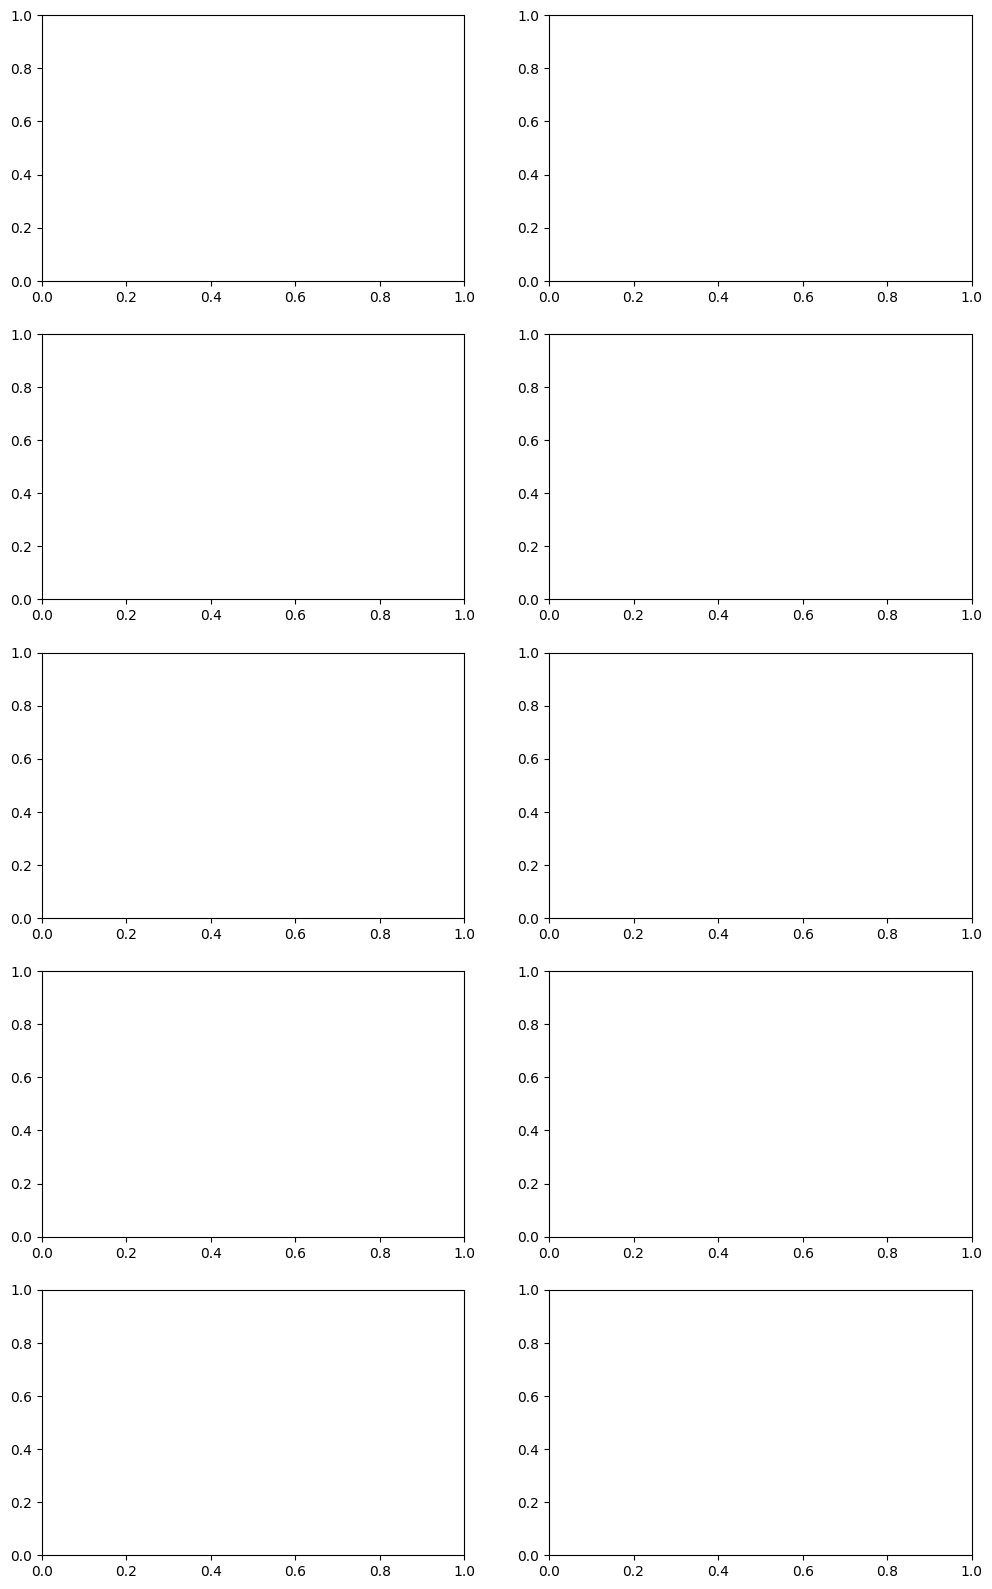

In [28]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Choose a disease exactly as it appears in your CSV
disease = "Early_blight"

train = df[(df["disease"] == disease) & (df["split"] == "train")].sample(5, random_state=42)

val = df[(df["disease"] == disease) & (df["split"] == "val")].sample(5, random_state=42)

fig, axes = plt.subplots(5, 2, figsize=(12, 20))

for i in range(5):
    for j, row in enumerate([train.iloc[i], val.iloc[i]]):
        img_path = IMAGE_ROOT / row["path"]
        img = Image.open(img_path).convert("RGB")

        axes[i, j].imshow(img)
        axes[i, j].set_title("TRAIN" if j == 0 else "VALIDATION")
        axes[i, j].axis("off")

plt.suptitle(disease, fontsize=16)
plt.tight_layout()
plt.show()

In [30]:
from pathlib import Path

IMAGE_ROOT = Path("/content/plantvillage")

In [31]:
image_path = IMAGE_ROOT / df.iloc[0]["path"]
print(image_path)
print("Exists:", image_path.exists())

/content/plantvillage/raw/color/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG
Exists: True


In [33]:
from pathlib import Path

SEARCH_ROOTS = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
]


def find_image(relative_path):
    relative_path = Path(relative_path)

    # Try direct paths
    for root in SEARCH_ROOTS:
        candidate = root / relative_path
        if candidate.exists():
            return candidate

    # Search by filename
    for root in SEARCH_ROOTS:
        if root.exists():
            matches = list(root.rglob(relative_path.name))
            if matches:
                return matches[0]

    return None

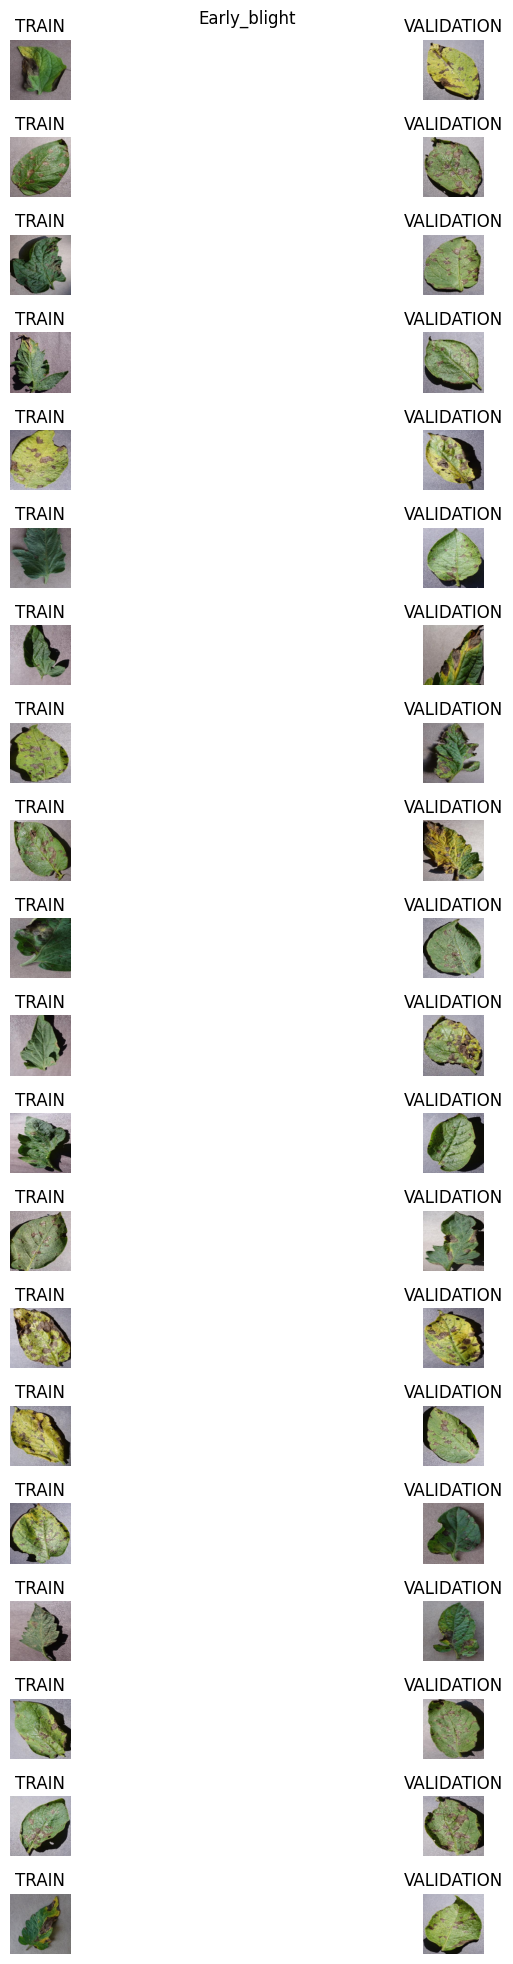

In [47]:
import matplotlib.pyplot as plt
from PIL import Image

disease = "Early_blight"

train = df[(df["disease"] == disease) & (df["split"] == "train")].sample(20, random_state=42)
val = df[(df["disease"] == disease) & (df["split"] == "val")].sample(20, random_state=42)

fig, axes = plt.subplots(20, 2, figsize=(12, 20))

for i in range(20):
    for j, row in enumerate([train.iloc[i], val.iloc[i]]):
        img_path = find_image(row["path"])

        if img_path is None:
            axes[i, j].set_title("IMAGE NOT FOUND")
            axes[i, j].axis("off")
            continue

        img = Image.open(img_path).convert("RGB")
        axes[i, j].imshow(img)
        axes[i, j].set_title("TRAIN" if j == 0 else "VALIDATION")
        axes[i, j].axis("off")

plt.suptitle(disease)
plt.tight_layout()
plt.show()

Total images: 1000
Training images: 732
Validation images: 132


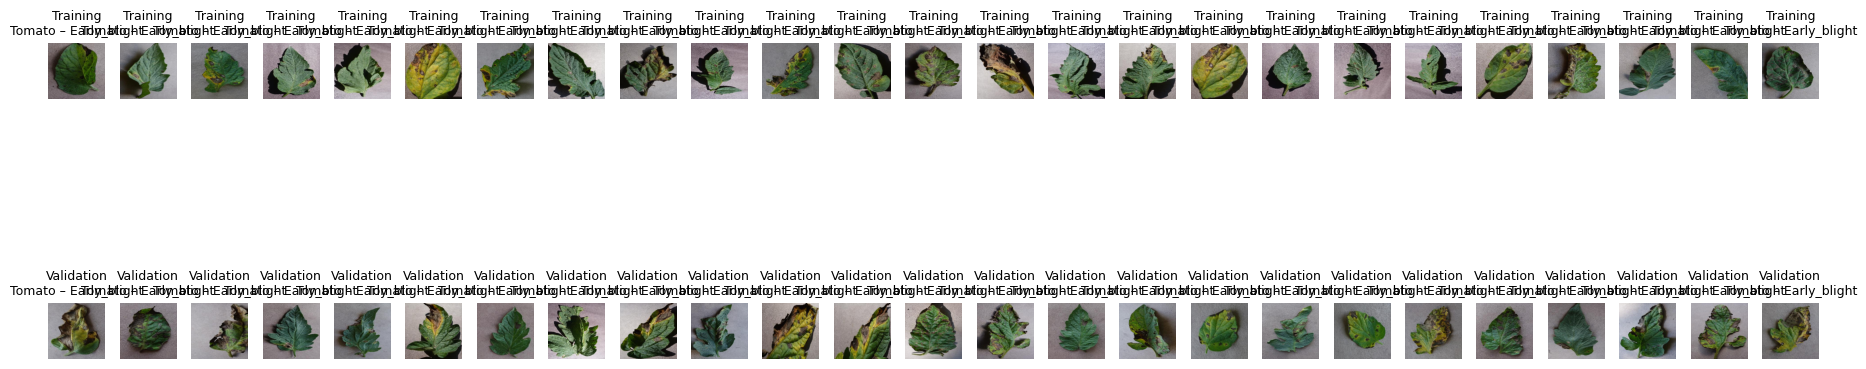

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

# Load your manifest
df = pd.read_csv("splits_all_38c.csv")

# Dataset root
IMAGE_ROOT = Path("/content/plantvillage")

# Select Tomato Early Blight
tomato_early = df[
    (df["crop"].str.lower() == "tomato") & (df["disease"].str.lower() == "early_blight")
]

print("Total images:", len(tomato_early))
print("Training images:", (tomato_early["split"] == "train").sum())
print("Validation images:", (tomato_early["split"] == "val").sum())

# Randomly select 5 from each split
train_samples = tomato_early[tomato_early["split"] == "train"].sample(
    n=min(25, (tomato_early["split"] == "train").sum()), random_state=42
)

val_samples = tomato_early[tomato_early["split"] == "val"].sample(
    n=min(25, (tomato_early["split"] == "val").sum()), random_state=42
)

# Display images
fig, axes = plt.subplots(2, 25, figsize=(18, 7))

for row, samples, split_name in [(0, train_samples, "Training"), (1, val_samples, "Validation")]:
    for col, (_, sample) in enumerate(samples.iterrows()):
        image_path = IMAGE_ROOT / sample["path"]
        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(
            f"{split_name}\n{sample['crop']} – {sample['disease']}", fontsize=9
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()